<a href="https://colab.research.google.com/github/shristeca/SETU---Data-Handling-and-Infrastructure-/blob/main/Project_AI_Infra_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Project AI Infra - Exploratory Data Analysis -M2

##Install Required Libraries

In [68]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [69]:
import os
import requests
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
import seaborn as sns
import matplotlib.pyplot as plt

##Import Dataset

In [70]:
## impoting dataset from kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sergionefedov/credit-risk-dataset-50k-loans-10-sectors")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'credit-risk-dataset-50k-loans-10-sectors' dataset.
Path to dataset files: /kaggle/input/credit-risk-dataset-50k-loans-10-sectors


In [71]:
## Get all the csv's in the file path
for file_name in os.listdir(path):
 print("FILE =", file_name)

FILE = macro_stress_scenarios.csv
FILE = payment_history.csv
FILE = portfolio_metrics.csv
FILE = payment_history_dictionary.csv
FILE = loan_portfolio.csv
FILE = credit_ratings.csv
FILE = vintage_analysis.csv


In [72]:
#Load all CSV'S

datasets = {}

for file_name in os.listdir(path):

    if file_name.endswith(".csv"):

        file_path = os.path.join(path, file_name)

        datasets[file_name] = pd.read_csv(file_path)

print(f"Loaded {len(datasets)} datasets")

Loaded 7 datasets


##EDA Summary - Quick Analysis of all 7 datasets

In [73]:
#Check if all 7 csv's all available
datasets.keys()

dict_keys(['macro_stress_scenarios.csv', 'payment_history.csv', 'portfolio_metrics.csv', 'payment_history_dictionary.csv', 'loan_portfolio.csv', 'credit_ratings.csv', 'vintage_analysis.csv'])

####Check the number of columns and rows in every dataset

In [74]:
for name, df in datasets.items():

    print("\n" + "="*60)
    print(name)
    print("="*60)

    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())


macro_stress_scenarios.csv
Shape: (60, 16)

Columns:
['scenario', 'gdp_shock_pp', 'unemp_shock_pp', 'rate_shock_pp', 'credit_spread_bps', 'sector', 'base_pd', 'stressed_pd', 'pd_uplift_pp', 'pd_multiplier', 'base_lgd', 'stressed_lgd', 'total_ead', 'expected_loss_base', 'expected_loss_stress', 'el_increase_pct']

payment_history.csv
Shape: (1212815, 13)

Columns:
['loan_id', 'month_on_book', 'payment_date', 'scheduled_payment', 'actual_payment', 'outstanding_balance', 'interest_component', 'principal_component', 'dpd', 'dpd_bucket', 'missed_payment', 'cumulative_missed', 'utilization']

portfolio_metrics.csv
Shape: (120, 16)

Columns:
['date', 'n_active_loans', 'total_ead', 'total_el', 'total_rwa', 'el_rate', 'avg_pd', 'avg_lgd', 'var_99', 'cvar_995', 'sector_hhi', 'new_defaults', 'gdp_growth', 'unemployment', 'policy_rate', 'credit_spread_bps']

payment_history_dictionary.csv
Shape: (13, 3)

Columns:
['column', 'type', 'description']

loan_portfolio.csv
Shape: (50000, 24)

Columns:
['

###Sample values in each file

In [75]:
for name, df in datasets.items():

    print("\n" + "="*60)
    print(name)
    print("="*60)

    print(df.head(3))


macro_stress_scenarios.csv
   scenario  gdp_shock_pp  unemp_shock_pp  rate_shock_pp  credit_spread_bps  \
0  baseline           0.0             0.0            0.0                  0   
1  baseline           0.0             0.0            0.0                  0   
2  baseline           0.0             0.0            0.0                  0   

        sector   base_pd  stressed_pd  pd_uplift_pp  pd_multiplier  base_lgd  \
0   Financials  0.022308     0.022308           0.0            1.0      0.45   
1  Real_Estate  0.022656     0.022656           0.0            1.0      0.40   
2     Consumer  0.021524     0.021524           0.0            1.0      0.55   

   stressed_lgd     total_ead  expected_loss_base  expected_loss_stress  \
0          0.45  3.016669e+10        3.161070e+08          3.028334e+08   
1          0.40  2.530543e+10        2.617922e+08          2.293309e+08   
2          0.55  5.049910e+09        6.904421e+07          5.978082e+07   

   el_increase_pct  
0           

###Check for missingness in each file

In [76]:
for name, df in datasets.items():

    print("\n" + "="*60)
    print(name)
    print("="*60)

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    print(missing)


macro_stress_scenarios.csv
Series([], dtype: int64)

payment_history.csv
utilization    965721
dtype: int64

portfolio_metrics.csv
Series([], dtype: int64)

payment_history_dictionary.csv
Series([], dtype: int64)

loan_portfolio.csv
default_date          43050
recovery_rate         43050
loss_given_default    43050
dtype: int64

credit_ratings.csv
Series([], dtype: int64)

vintage_analysis.csv
Series([], dtype: int64)


###EDA on Loan dataset
####Descriptive Analysis

In [77]:
#Sample records in Loan Portfolio file
loan_df = datasets['loan_portfolio.csv']
print(loan_df.head(3))

   loan_id origination_date maturity_date  maturity_months       sector  \
0  L000001       2017-10-01    2019-10-01               24   Technology   
1  L000002       2016-06-01    2020-06-01               48   Healthcare   
2  L000003       2023-08-01    2024-12-31               36  Real_Estate   

   loan_type collateral initial_rating  credit_score         ead  ...  \
0   mortgage    secured              B           704  1035611.99  ...   
1  term_loan  unsecured              A           702   800786.92  ...   
2       bond    secured            BBB           699  4327864.12  ...   

   pd_annual     lgd        el  unexpected_loss        rwa  defaulted  \
0   0.041076  0.7858  33426.80        161508.03  442905.14          0   
1   0.000887  0.7034    499.82         16771.62    6622.66          0   
2   0.002622  0.5503   6243.54        121781.72   82726.94          0   

   default_date  survival_months  recovery_rate  loss_given_default  
0           NaN               24           

In [78]:
#As is Datatypes of Each column
print(loan_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   loan_id             50000 non-null  object 
 1   origination_date    50000 non-null  object 
 2   maturity_date       50000 non-null  object 
 3   maturity_months     50000 non-null  int64  
 4   sector              50000 non-null  object 
 5   loan_type           50000 non-null  object 
 6   collateral          50000 non-null  object 
 7   initial_rating      50000 non-null  object 
 8   credit_score        50000 non-null  int64  
 9   ead                 50000 non-null  float64
 10  coupon_rate         50000 non-null  float64
 11  leverage            50000 non-null  float64
 12  interest_coverage   50000 non-null  float64
 13  debt_to_equity      50000 non-null  float64
 14  pd_annual           50000 non-null  float64
 15  lgd                 50000 non-null  float64
 16  el  

##Leakage Columns
###Question to Ask: Would I know this information on the day I access the loan?

In [79]:
remove_cols = ['pd_annual', 'el', 'unexpected_loss','loss_given_default', 'default_date', 'survival_months', 'rwa', 'recovery_rate', 'lgd']
loan_df = loan_df.drop(columns=remove_cols, errors='ignore')

Remaining columns after removal of leakage columns

In [80]:
loan_df.columns

Index(['loan_id', 'origination_date', 'maturity_date', 'maturity_months',
       'sector', 'loan_type', 'collateral', 'initial_rating', 'credit_score',
       'ead', 'coupon_rate', 'leverage', 'interest_coverage', 'debt_to_equity',
       'defaulted'],
      dtype='object')

In [81]:
##Changing both the date columns into datetime variables for future analysis
loan_df['origination_date'].dtype
loan_df['origination_date'] = pd.to_datetime(loan_df['origination_date'])

loan_df['maturity_date'].dtype
loan_df['maturity_date'] = pd.to_datetime(loan_df['maturity_date'])


In [82]:
##Datatype After Change
print(loan_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   loan_id            50000 non-null  object        
 1   origination_date   50000 non-null  datetime64[ns]
 2   maturity_date      50000 non-null  datetime64[ns]
 3   maturity_months    50000 non-null  int64         
 4   sector             50000 non-null  object        
 5   loan_type          50000 non-null  object        
 6   collateral         50000 non-null  object        
 7   initial_rating     50000 non-null  object        
 8   credit_score       50000 non-null  int64         
 9   ead                50000 non-null  float64       
 10  coupon_rate        50000 non-null  float64       
 11  leverage           50000 non-null  float64       
 12  interest_coverage  50000 non-null  float64       
 13  debt_to_equity     50000 non-null  float64       
 14  defaul

Load EDA transformed data into Loan_df_EDA_transformed

In [83]:
Loan_df_EDA_transformed = loan_df.copy()

In [84]:
print(Loan_df_EDA_transformed.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   loan_id            50000 non-null  object        
 1   origination_date   50000 non-null  datetime64[ns]
 2   maturity_date      50000 non-null  datetime64[ns]
 3   maturity_months    50000 non-null  int64         
 4   sector             50000 non-null  object        
 5   loan_type          50000 non-null  object        
 6   collateral         50000 non-null  object        
 7   initial_rating     50000 non-null  object        
 8   credit_score       50000 non-null  int64         
 9   ead                50000 non-null  float64       
 10  coupon_rate        50000 non-null  float64       
 11  leverage           50000 non-null  float64       
 12  interest_coverage  50000 non-null  float64       
 13  debt_to_equity     50000 non-null  float64       
 14  defaul

Check Missing Values in each columns in loan_df

In [85]:
#Null counts
#Missing value patterns
loan_df.isnull().sum()

,0
loan_id,0
origination_date,0
maturity_date,0
maturity_months,0
sector,0
loan_type,0
collateral,0
initial_rating,0
credit_score,0
ead,0


Check Duplicates

In [86]:
#Are there duplicate rows?
#Should they be removed?
loan_df.duplicated().sum()

np.int64(0)

##Target Variable Analysis
###0 = Defaulted
###1= Not Defaulted


In [87]:
#Count of Defaulted/Non Defaulted loans
loan_df['defaulted'].value_counts()

,count
defaulted,
0,43050
1,6950


In [88]:
#Percentage of loans defaulted/non-defaulted
loan_df['defaulted'].value_counts(normalize=True)*100

,proportion
defaulted,
0,86.1
1,13.9


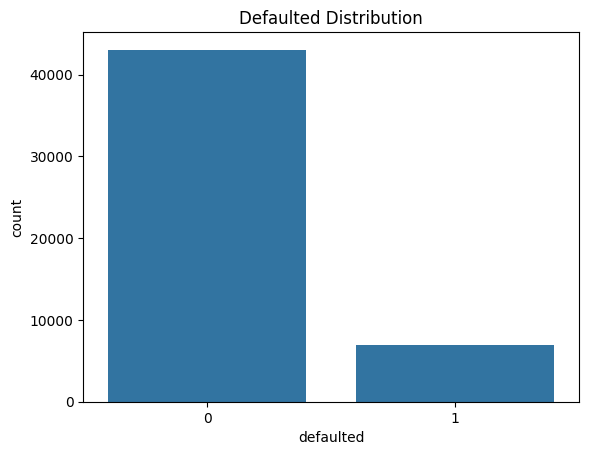

In [89]:
#Visualize the Target variable
sns.countplot(data=loan_df, x= 'defaulted')
plt.title('Defaulted Distribution')
plt.show()

##Univariate Analysis
###Analyse each feature individually

In [90]:
#Separate Numerical and Categorical Columns
num_cols = loan_df.select_dtypes(include=['int64','float64']).columns

cat_cols = loan_df.select_dtypes(include=['object','category']).columns

date_cols = loan_df.select_dtypes(include=['datetime64']).columns

print("Numerical Columns:",num_cols)

print("Categorical Columns:",cat_cols)

print("Date Columns:",date_cols)



Numerical Columns: Index(['maturity_months', 'credit_score', 'ead', 'coupon_rate', 'leverage',
       'interest_coverage', 'debt_to_equity', 'defaulted'],
      dtype='object')
Categorical Columns: Index(['loan_id', 'sector', 'loan_type', 'collateral', 'initial_rating'], dtype='object')
Date Columns: Index(['origination_date', 'maturity_date'], dtype='object')


###Numerical Feature Analysis

In [91]:
#Descriptive Statistics
loan_df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
maturity_months,50000.0,5.397048e+01,2.671625e+01,12.0,36.000,4.800000e+01,6.000000e+01,1.200000e+02
credit_score,50000.0,7.149826e+02,5.089341e+01,518.0,679.000,7.150000e+02,7.500000e+02,8.500000e+02
ead,50000.0,3.298605e+06,6.661943e+06,50000.0,548268.505,1.389712e+06,3.425439e+06,3.611778e+08
coupon_rate,50000.0,3.079087e+00,1.103558e+00,1.0,2.357,3.063500e+00,3.735000e+00,7.531000e+00
leverage,50000.0,6.913779e+00,3.686415e+00,0.5,4.060,6.080000e+00,9.070000e+00,1.500000e+01
interest_coverage,50000.0,3.764089e+00,2.014019e+00,0.5,2.370,3.310000e+00,4.650000e+00,2.000000e+01
debt_to_equity,50000.0,2.090884e+00,1.570126e+00,0.1,1.030,1.650000e+00,2.640000e+00,1.000000e+01
defaulted,50000.0,1.390000e-01,3.459500e-01,0.0,0.000,0.000000e+00,0.000000e+00,1.000000e+00


###Maturity Months:
The loan's term length

The profolio has loans with terms ranging from 12 -120 months with an average muturity around 54 months. Looks like most of them are medioum term loans with some long term loans pulling the average upwards.

###Credit Score
Higher score = lower risk

Borrowers range from poor credit quality (518) to excellent credit quality (850).Credit scores are well distributed across and appear approximately symmetric as the mean and median are almost identical.

###EAD (Exposure at Default)
The amount outstanding when a borrower defaults.

The csv contains some very large loans with extremely large exposures.  

###Coupon Rate
The interest rate charged on the loan.

With the average interest rate closer to the median most loans fall within a moderate interest rate range.

###Leverage
A measure of debt burden.

Most borrowers maintain moderate leverage levels, although a subset of highly leveraged firms may contribute disproportionately to default risk.

###Interest Coverage
Ability to pay interest payments.

Interest coverage ranges from 0.5 to 20, with an average of 3.76. Since the mean (3.76) is slightly higher than the median (3.31), a small number of borrowers have very strong repayment capacity. Overall, most borrowers appear able to service their debt comfortably.

###Debt-to-equity
Measures debt relative to shareholder equity.

Debt-to-equity ratios range from 0.1 to 10, with an average of 2.09. The mean is higher than the median (1.65), indicating that some borrowers rely heavily on debt financing. These highly leveraged borrowers may face greater financial risk and default risk.

##Histogram based on the above stats

Descriptive statistics tell you the numbers, while histograms show the shape of the distribution. Together they help you understand whether the variable is balanced, skewed, concentrated, or contains extreme observations.

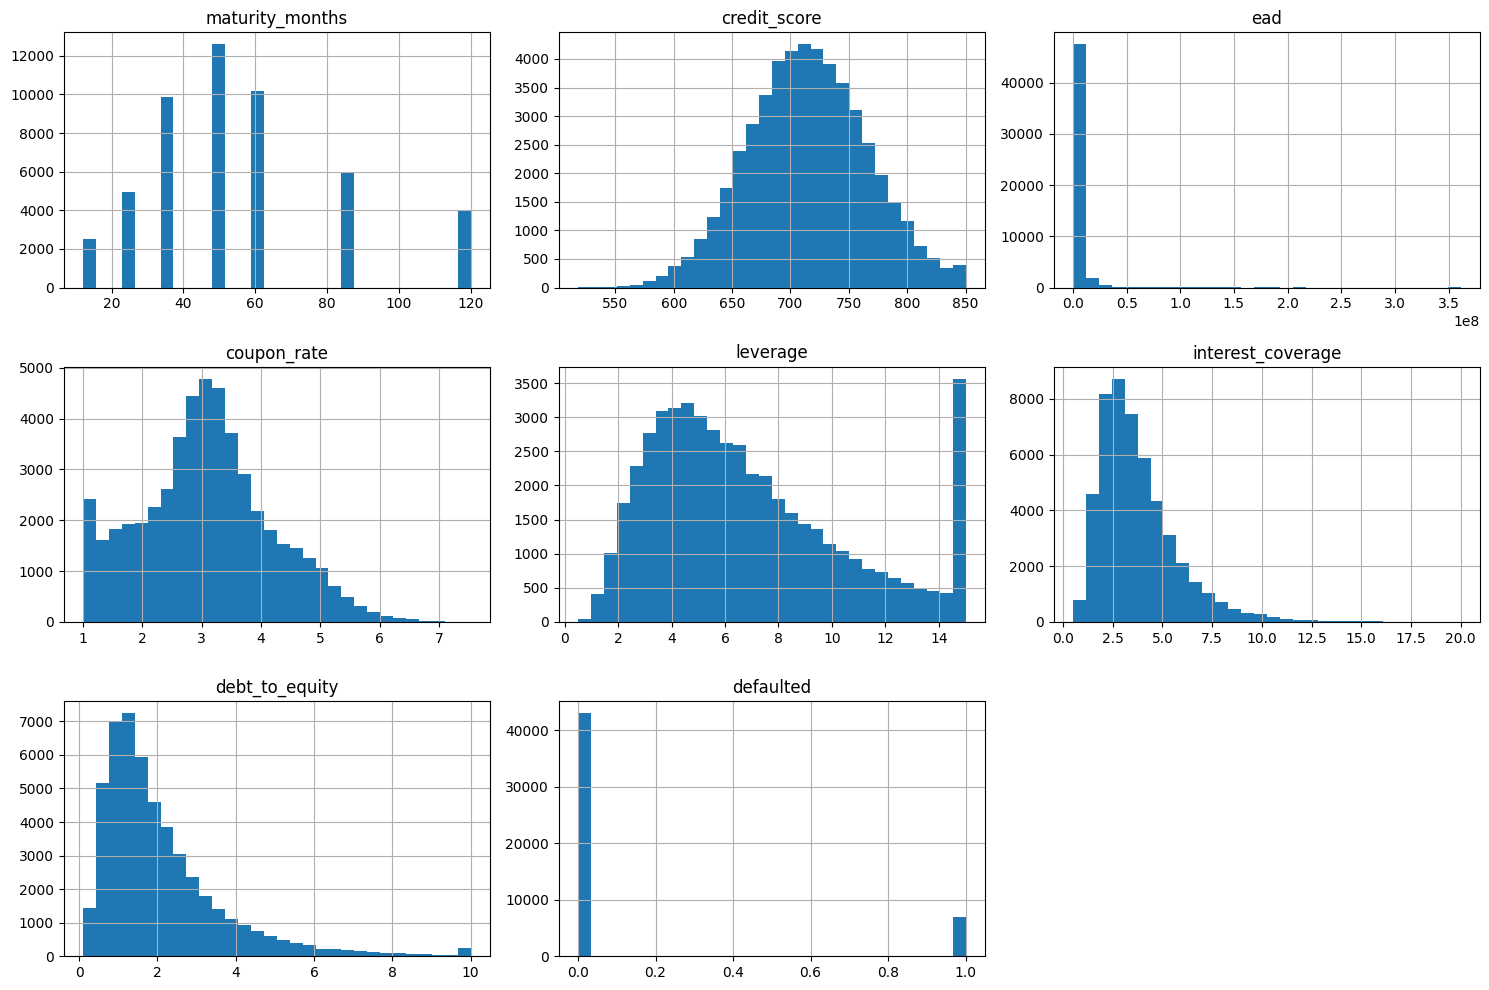

In [92]:
#Look for distribution of variables
import matplotlib.pyplot as plt

loan_df[num_cols].hist(
    figsize=(15,10),
    bins=30
)

plt.tight_layout()
plt.show()


###Skewness

In [93]:
loan_df[num_cols].skew().round(2).sort_values(ascending=False)

,0
ead,10.62
defaulted,2.09
debt_to_equity,1.98
interest_coverage,1.77
maturity_months,0.99
leverage,0.75
coupon_rate,0.24
credit_score,0.03


EAD (10.62) is highly positively skewed, indicating that a few loans have much larger exposures than the rest of the portfolio.

Debt-to-equity (1.98), interest coverage (1.77), and leverage (0.75) are also positively skewed, suggesting the presence of borrowers with significantly different risk profiles.

In contrast, credit score (0.03) and coupon rate (0.24) are approximately symmetric and appear well distributed.

Overall: Most risk-related variables are right-skewed, while credit score and coupon rate show balanced distributions.

###Correlation Analysis

The correlation analysis indicates that most variables have weak linear relationships with each other, suggesting a low risk of multicollinearity. Credit score shows the strongest relationship with the target variable (-0.218), indicating that borrowers with lower credit scores are more likely to default. Coupon rate exhibits a weak positive relationship with default (0.111), while EAD, leverage, interest coverage and debt-to-equity show little or no linear relationship with default. Overall, credit score appears to be the most informative predictor among the selected variables.

In [94]:
loan_df[num_cols].corr()

,maturity_months,credit_score,ead,coupon_rate,leverage,interest_coverage,debt_to_equity,defaulted
maturity_months,1.000000,0.004726,-0.003231,-0.008590,0.001744,0.002185,-0.000868,0.134930
credit_score,0.004726,1.000000,0.000141,-0.170225,-0.002871,0.005927,-0.000196,-0.217579
ead,-0.003231,0.000141,1.000000,-0.003301,-0.004626,-0.001726,-0.002485,-0.001420
coupon_rate,-0.008590,-0.170225,-0.003301,1.000000,0.002853,0.004374,0.000549,0.111410
leverage,0.001744,-0.002871,-0.004626,0.002853,1.000000,0.004084,0.000707,0.000948
interest_coverage,0.002185,0.005927,-0.001726,0.004374,0.004084,1.000000,-0.003304,-0.009880
debt_to_equity,-0.000868,-0.000196,-0.002485,0.000549,0.000707,-0.003304,1.000000,-0.003118
defaulted,0.134930,-0.217579,-0.001420,0.111410,0.000948,-0.009880,-0.003118,1.000000


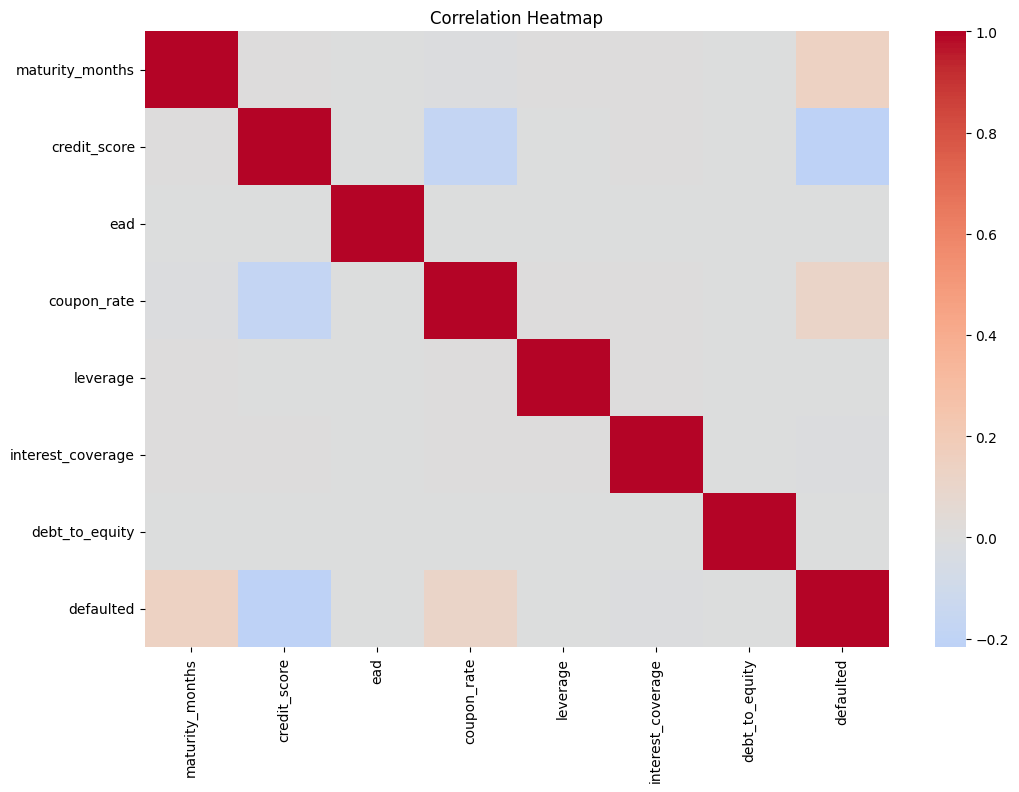

In [95]:
plt.figure(figsize=(12,8))

sns.heatmap(
    loan_df[num_cols].corr(),
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Heatmap")
plt.show()

##Numerical Vs Target Comparison

###What credit score band does the defaulted loans fall under?

More than 30% of the defaulted loans fall under the loweat credit score category compared to loans with higher credit scores.

In [96]:
loan_df['score_band'] = pd.qcut(
    loan_df['credit_score'],
    10
)

default_rate = loan_df.groupby('score_band')['defaulted'].mean()*100

/tmp/ipykernel_1441/1424222017.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  default_rate = loan_df.groupby('score_band')['defaulted'].mean()*100


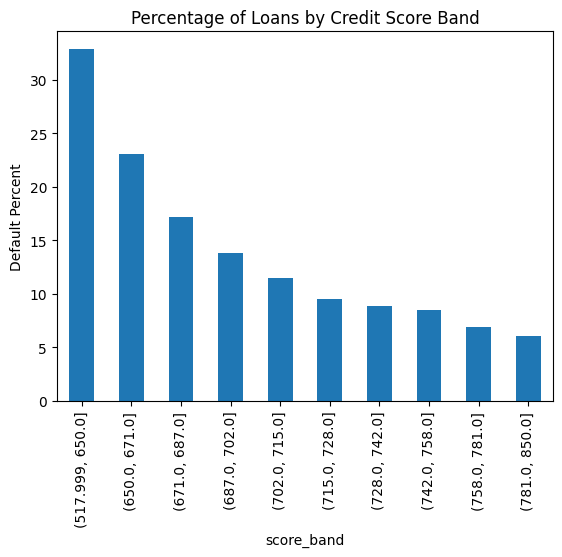

In [97]:
default_rate.plot.bar()
plt.title('Percentage of Loans by Credit Score Band')
plt.ylabel('Default Percent')
plt.show()

###Are defaulted loans charged higher interest rates on average?

The defaulted loans tend to have higher interest rates on average.

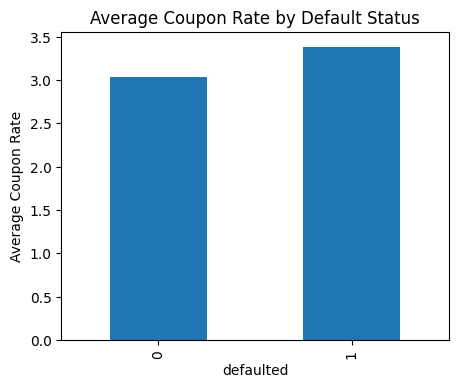

In [98]:
loan_df.groupby('defaulted')['coupon_rate'].mean().plot(
    kind='bar',
    figsize=(5,4)
)

plt.title('Average Coupon Rate by Default Status')
plt.ylabel('Average Coupon Rate')
plt.show()

###Do defaulted loans generally have longer term than non-defaulted loans?


Default rates increase as loan maturity increases, suggesting that longer-term loans are exposed to greater uncertainty and therefore carry a higher risk of default.

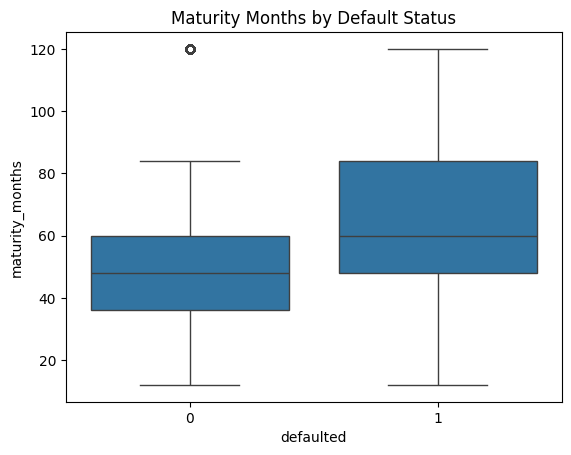

In [99]:
sns.boxplot(
    data=loan_df,
    x='defaulted',
    y='maturity_months'
)

plt.title('Maturity Months by Default Status')
plt.show()

In [100]:
loan_df[num_cols].mean().round(2)


,0
maturity_months,53.97
credit_score,714.98
ead,3298604.67
coupon_rate,3.08
leverage,6.91
interest_coverage,3.76
debt_to_equity,2.09
defaulted,0.14


##Categorical Analysis

In [101]:
for col in cat_cols:
    print("\n", col)
    print(loan_df[col].value_counts())


 loan_id
loan_id
L049984    1
L049983    1
L049982    1
L049981    1
L049980    1
          ..
L000005    1
L000004    1
L000003    1
L000002    1
L000001    1
Name: count, Length: 50000, dtype: int64

 sector
sector
Energy         5132
Telecom        5077
Consumer       5043
Financials     5023
Industrials    5012
Healthcare     4982
Technology     4959
Utilities      4959
Retail         4951
Real_Estate    4862
Name: count, dtype: int64

 loan_type
loan_type
term_loan    17594
mortgage     12262
revolving    10158
bond          7458
lease         2528
Name: count, dtype: int64

 collateral
collateral
secured              22657
unsecured            17398
partially_secured     9945
Name: count, dtype: int64

 initial_rating
initial_rating
BBB    14001
BB     10918
A       7571
B       7559
CCC     4478
AA      3944
AAA     1529
Name: count, dtype: int64


##Sector Analysis

###Is the number of loans balanced across all 10 sectors
Looking at the count all sectors have almost equal no of loans.

In [102]:
loan_df['sector'].value_counts()

,count
sector,
Energy,5132
Telecom,5077
Consumer,5043
Financials,5023
Industrials,5012
Healthcare,4982
Technology,4959
Utilities,4959
Retail,4951


###Percentage defaulted in across each sector
All sectors are same with Financial sectors having a slightly more loans defaulted.

In [103]:
#default rate by sector
sector_default = loan_df.groupby('sector')['defaulted'].mean().round(2)*100
sector_default

,defaulted
sector,
Consumer,14.0
Energy,14.0
Financials,15.0
Healthcare,13.0
Industrials,14.0
Real_Estate,14.0
Retail,14.0
Technology,14.0
Telecom,13.0


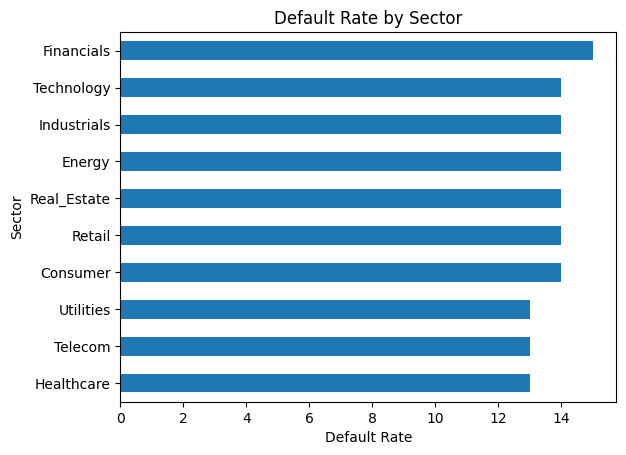

In [104]:
sector_default.sort_values().plot.barh()
plt.xlabel('Default Rate')
plt.ylabel('Sector')
plt.title('Default Rate by Sector')

plt.show()

##Rating Analysis

###Which ratings are most common in the portfolio?
From the graph below most loans fall under the 'BBB' rating

(AAA, AA, A)  → Lowest risk

BBB - Mid Range

(BB, B, CCC)  → Highest risk


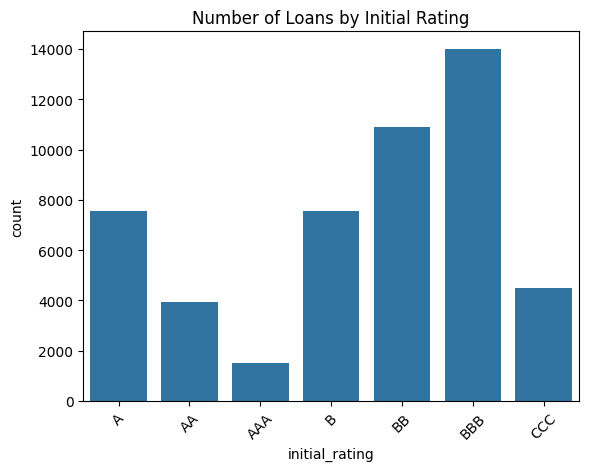

In [105]:
sns.countplot(
    data=loan_df,
    x='initial_rating',
    order=sorted(loan_df['initial_rating'].unique())
)

plt.title('Number of Loans by Initial Rating')
plt.xticks(rotation=45)
plt.show()

###Which rating has the highest no of defaulted loans
The rating 'CCC' has the maximum no of loans defaulted and 'AAA' to be the lowest.

In [106]:
loan_df.groupby('initial_rating')['defaulted'].sum().sort_values(ascending=False)

,defaulted
initial_rating,
CCC,2278
B,1650
BB,1220
BBB,986
A,484
AA,252
AAA,80


###How does the proportion of defaults change across rating grades?

With almost equal no of loans across all rating 'CCC' has more defaulted loans that the rest

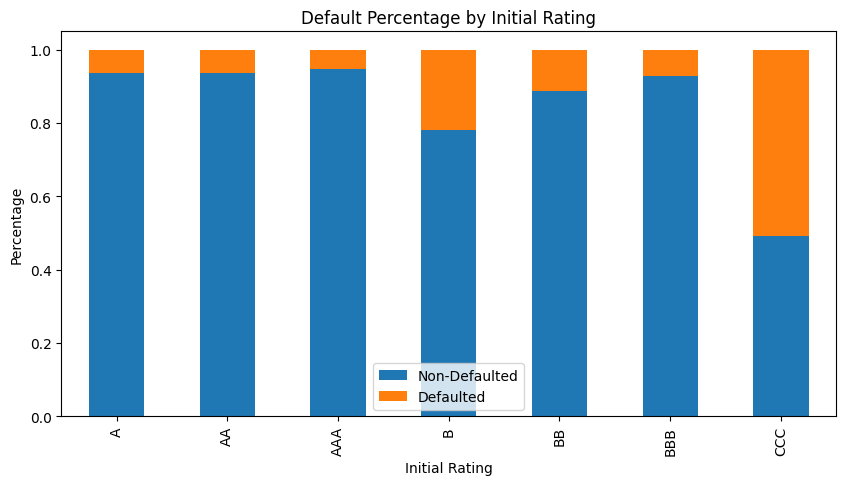

In [107]:
rating_default = pd.crosstab(
    loan_df['initial_rating'],
    loan_df['defaulted'],
    normalize='index'
)

rating_default.plot(
    kind='bar',
    stacked=True,
    figsize=(10,5)
)

plt.title('Default Percentage by Initial Rating')
plt.ylabel('Percentage')
plt.xlabel('Initial Rating')
plt.legend(['Non-Defaulted', 'Defaulted'])
plt.show()

##Loan Type Analysis

In [108]:
pd.crosstab(
 loan_df['loan_type'],
 loan_df['defaulted']
)


defaulted,0,1
loan_type,,
bond,6494,964
lease,2155,373
mortgage,10512,1750
revolving,8745,1413
term_loan,15144,2450


###How many defaulted and non-defaulted loans exist within each loan type

Most loans fall under the term-loan category with more no of loans defaulted. But the average defaulted across all categories are almost close enough.

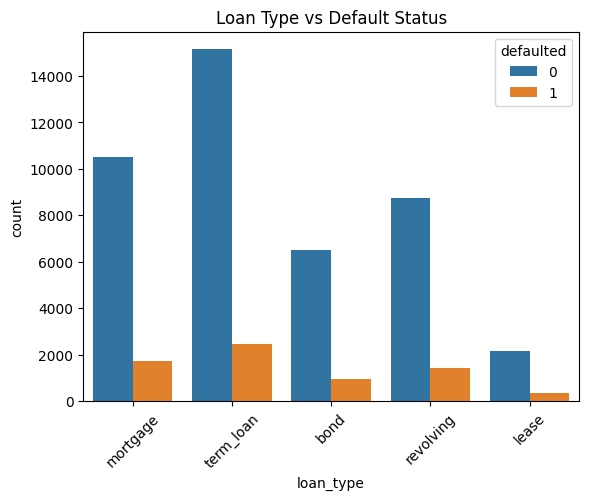

In [109]:
sns.countplot(
    data=loan_df,
    x='loan_type',
    hue='defaulted'
)

plt.title('Loan Type vs Default Status')
plt.xticks(rotation=45)
plt.show()

In [110]:
loan_type_default = (
    loan_df.groupby('loan_type')['defaulted']
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print(loan_type_default)

loan_type
lease        14.75
mortgage     14.27
term_loan    13.93
revolving    13.91
bond         12.93
Name: defaulted, dtype: float64


###Collateral Analysis

The loan dataset has more secured loans but the default rate is not affected by having a secured collateral

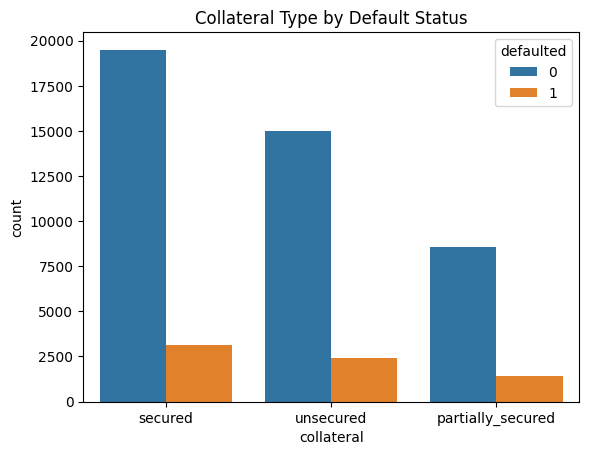

In [111]:
sns.countplot(
    data=loan_df,
    x='collateral',
    hue='defaulted'
)

plt.title('Collateral Type by Default Status')
plt.show()

##Date Variable analysis

In [112]:
loan_df['origination_year'] = loan_df['origination_date'].dt.year
loan_df[['origination_date', 'origination_year']].head()

,origination_date,origination_year
0,2017-10-01,2017
1,2016-06-01,2016
2,2023-08-01,2023
3,2016-04-01,2016
4,2015-10-01,2015


###Orgination of Loans every year

From 2015 - 2023 there are almost equivalent no of loans

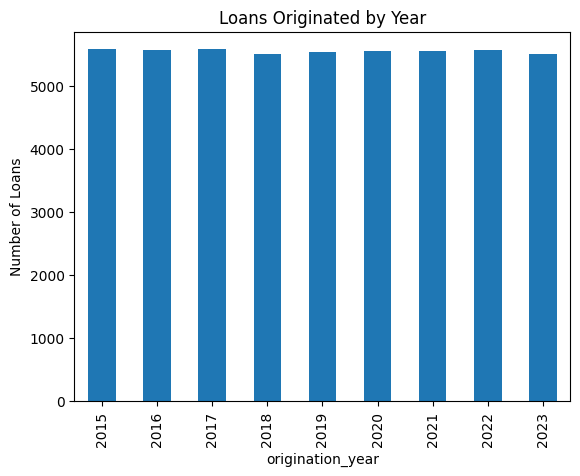

In [113]:
loan_df['origination_year'].value_counts().sort_index().plot.bar()

plt.title('Loans Originated by Year')
plt.ylabel('Number of Loans')
plt.show()

###Were loans issued in certain years riskier than others?

Loans issued in the year 2020 were at higher default rate.

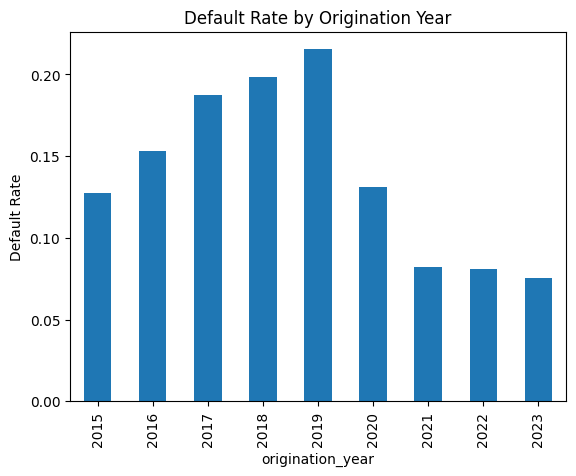

In [114]:
loan_df.groupby('origination_year')['defaulted'].mean().plot.bar()

plt.title('Default Rate by Origination Year')
plt.ylabel('Default Rate')
plt.show()

###Did borrower quality improve or deteriorate over time?

The average credit score remains around 715 every year.
This suggests that the credit quality of borrowers entering the portfolio has remained largely unchanged throughout the observation period.



(700.0, 720.0)

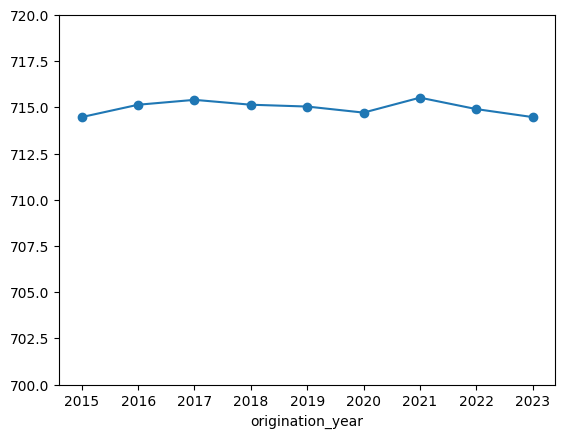

In [115]:
loan_df.groupby('origination_year')['credit_score'].mean().plot.line(marker='o')
plt.ylim(700, 720)

###Has the composition of the portfolio changed over time?

There has not been any significant changes in compositions across sectors.

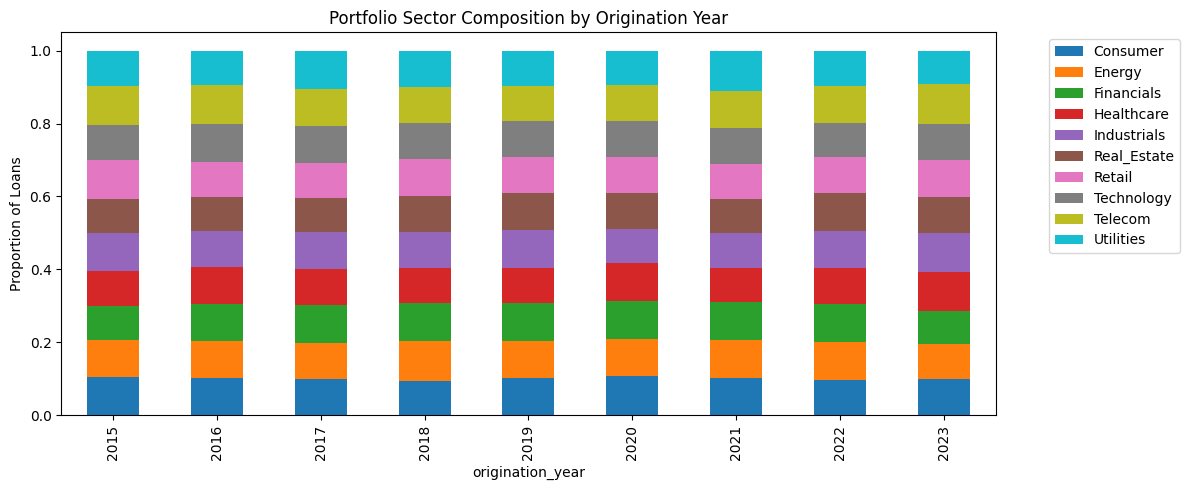

In [116]:
pd.crosstab(
    loan_df['origination_year'],
    loan_df['sector'],
    normalize='index'
).plot(
    kind='bar',
    stacked=True,
    figsize=(12,5)
)

plt.ylabel('Proportion of Loans')
plt.title('Portfolio Sector Composition by Origination Year')
plt.legend(bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [117]:
print(loan_df[:5])

   loan_id origination_date maturity_date  maturity_months       sector  \
0  L000001       2017-10-01    2019-10-01               24   Technology   
1  L000002       2016-06-01    2020-06-01               48   Healthcare   
2  L000003       2023-08-01    2024-12-31               36  Real_Estate   
3  L000004       2016-04-01    2024-12-31              120  Real_Estate   
4  L000005       2015-10-01    2019-10-01               48       Energy   

   loan_type collateral initial_rating  credit_score         ead  coupon_rate  \
0   mortgage    secured              B           704  1035611.99        3.776   
1  term_loan  unsecured              A           702   800786.92        3.895   
2       bond    secured            BBB           699  4327864.12        4.365   
3  term_loan    secured              B           641  3810461.19        3.749   
4       bond  unsecured            CCC           597  2925538.53        5.231   

   leverage  interest_coverage  debt_to_equity  defaulted     

### Load the transformed file into GCS

In [122]:
from google.colab import auth
auth.authenticate_user()

from google.cloud import storage
client = storage.Client()

In [125]:
from google.cloud import storage

bucket_name = "credit-risk-raw-data"

client = storage.Client()
bucket = client.bucket(bucket_name)
blob = bucket.blob("processed/loan_portfolio_transformed_EDA_V1.csv")

blob.upload_from_string(
    Loan_df_EDA_transformed.to_csv(index=False),
    content_type="text/csv"
)

print("Upload completed")

Upload completed
